<a href="https://colab.research.google.com/github/rpasquini/herramientas-econometricas/blob/main/Diferencias_en_Diferencias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diferencias en diferencias

Este notebook acompaña las slides del Día 7. Ejemplos:

1. **Un asistente de IA para vendedores** (datos simulados del libro *Econometrics with Simulations*): conocemos el efecto verdadero, así que podemos juzgar cada estimador.
2. **Card y Krueger (1994)**: ¿el salario mínimo reduce el empleo? Datos originales; replicamos la tabla del paper.
3. **MLDA (edad mínima para beber)**: panel de 51 estados, efectos fijos y tendencias estatales (Angrist y Pischke).
4. **Salario mínimo en condados** (`mpdta`, Callaway y Sant'Anna, 2021): diseño escalonado, TWFE vs. estimadores robustos.
5. **Alquileres en CABA y COVID** (caso de la edición anterior): ¿subieron más los alquileres de los departamentos con espacio al aire libre?

Plan:
1. DD $2\times2$ en simulación: tabla, regresión, tendencias diferenciales
2. Card y Krueger
3. Tendencias paralelas: pre-tendencias, potencia, forma funcional, errores estándar
4. MLDA: efectos fijos y tendencias estatales
5. Diseños escalonados: TWFE, Goodman-Bacon y Callaway--Sant'Anna
6. Salario mínimo en condados
7. Alquileres y COVID
8. Ejercicios

## 0. Preparación

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings('ignore')
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})
BLUE, ORANGE, GREY, GREEN, RED = '#1f77b4', '#ff7f0e', '#888888', '#2ca02c', '#cd5c5c'

BASE = 'https://raw.githubusercontent.com/rpasquini/herramientas-econometricas/main/datos/'
def leer(nombre):
    # primero busca el archivo en la carpeta datos/ (si se corre desde el repo); si no, lo baja de GitHub
    import os
    ruta = os.path.join('datos', nombre)
    return pd.read_csv(ruta if os.path.exists(ruta) else BASE + nombre)

rng = np.random.default_rng(2026)

## 1. DD $2\times2$ en una simulación

Una empresa B2B lanza un asistente de IA para sus representantes de ventas. Algunas regiones lo reciben (`G=1`), otras no (`G=0`). Observamos las ventas **antes** y **después** (`post`). Los parámetros:

- $\tau$: efecto verdadero (ATT);
- $\alpha$: **brecha inicial** entre grupos (nivel);
- $\lambda$: **tendencia común** a ambos grupos;
- $\delta$: **tendencia diferencial** de las tratadas (violación de tendencias paralelas).

$$Y_{it}=50+\alpha\,G_i+\lambda\,\text{post}_t+\delta\,G_i\,\text{post}_t+\tau\,G_i\,\text{post}_t+\varepsilon_{it}$$

In [2]:
def simular_2x2(tau=15, alpha=10, lam=5, delta=0, n=200, sd=10, rng=rng):
    # n regiones por grupo, dos períodos (repeated cross-section)
    filas = []
    for G in (0, 1):
        for post in (0, 1):
            y = 50 + alpha * G + lam * post + (delta + tau) * G * post + rng.normal(0, sd, n)
            filas.append(pd.DataFrame({'y': y, 'G': G, 'post': post}))
    return pd.concat(filas, ignore_index=True)

def dd_medias(d):
    m = d.groupby(['G', 'post']).y.mean().unstack()
    return (m.loc[1, 1] - m.loc[1, 0]) - (m.loc[0, 1] - m.loc[0, 0]), m

d = simular_2x2()
dd, medias = dd_medias(d)
print(medias.round(2)); print('\nDD por medias:', round(dd, 3))
r = smf.ols('y ~ G * post', d).fit()
print('Coeficiente G:post (regresión):', round(r.params['G:post'], 3), ' EE:', round(r.bse['G:post'], 3))

post      0      1
G                 
0     50.74  55.18
1     60.28  80.41

DD por medias: 15.692
Coeficiente G:post (regresión): 15.692  EE: 1.456


**La tabla y la regresión dan el mismo número** (es una identidad algebraica: Apéndice A.2 de las slides). Ahora el gráfico, con el **contrafáctico** de las tratadas: lo que tenían antes más el cambio del control.

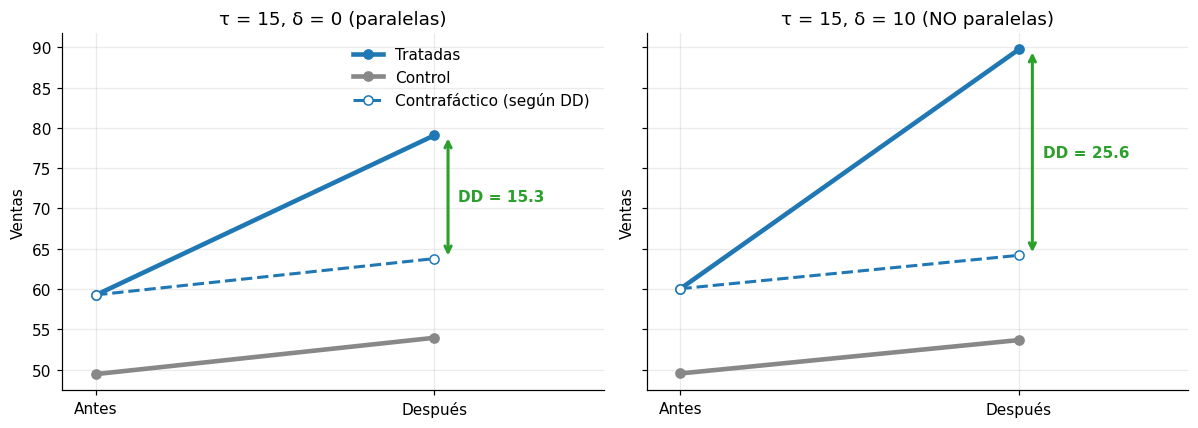

In [3]:
def grafico_2x2(d, tau_verdadero=None, ax=None, titulo=''):
    dd, m = dd_medias(d)
    ax = ax or plt.gca()
    ax.plot([0, 1], m.loc[1], 'o-', color=BLUE, lw=3, label='Tratadas')
    ax.plot([0, 1], m.loc[0], 'o-', color=GREY, lw=3, label='Control')
    cf = [m.loc[1, 0], m.loc[1, 0] + (m.loc[0, 1] - m.loc[0, 0])]
    ax.plot([0, 1], cf, 'o--', color=BLUE, mfc='white', lw=2, label='Contrafáctico (según DD)')
    ax.annotate('', xy=(1.04, m.loc[1, 1]), xytext=(1.04, cf[1]), arrowprops=dict(arrowstyle='<->', color=GREEN, lw=2))
    ax.text(1.07, (m.loc[1, 1] + cf[1]) / 2, f'DD = {dd:.1f}', color=GREEN, va='center', weight='bold')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Antes', 'Después']); ax.set_xlim(-.1, 1.5); ax.set_title(titulo)
    ax.set_ylabel('Ventas')

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
grafico_2x2(simular_2x2(tau=15), ax=axs[0], titulo='τ = 15, δ = 0 (paralelas)')
grafico_2x2(simular_2x2(tau=15, delta=10), ax=axs[1], titulo='τ = 15, δ = 10 (NO paralelas)')
axs[0].legend(frameon=False); plt.tight_layout(); plt.show()

### Variando $\tau$, $\alpha$ y $\lambda$

El DD **sigue a $\tau$** sin importar la brecha inicial ni la tendencia común: ambas se cancelan en la doble diferencia.

In [4]:
filas = []
for tau in [0, 5, 15, 30, 50]:
    for alpha, lam in [(0, 0), (10, 5), (40, 20)]:
        d = simular_2x2(tau=tau, alpha=alpha, lam=lam, n=2000)
        filas.append({'tau': tau, 'alpha': alpha, 'lambda': lam, 'DD': dd_medias(d)[0]})
pd.DataFrame(filas).pivot(index='tau', columns=['alpha', 'lambda'], values='DD').round(2)

alpha,0,10,40
lambda,0,5,20
tau,,,
0,-0.33,-0.20,0.25
5,5.52,4.87,4.38
15,14.64,14.59,15.67
30,29.14,30.31,30.26
50,49.85,49.76,49.30


### Tendencias diferenciales ($\delta\neq0$): el sesgo es exactamente $\delta$

Con $\delta\ne0$ el DD estima $\tau+\delta$. Un experimento de Monte Carlo (1.000 réplicas): la distribución del estimador queda **centrada en $\tau+\delta$**, no en $\tau$.

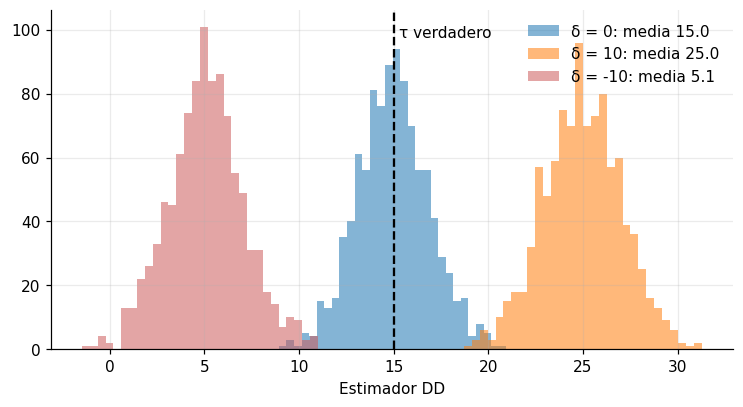

In [5]:
def mc_dd(delta, tau=15, R=1000, n=100):
    return np.array([dd_medias(simular_2x2(tau=tau, delta=delta, n=n))[0] for _ in range(R)])

fig, ax = plt.subplots(figsize=(8, 4))
for delta, c in [(0, BLUE), (10, ORANGE), (-10, RED)]:
    est = mc_dd(delta)
    ax.hist(est, bins=30, alpha=.55, color=c, label=f'δ = {delta}: media {est.mean():.1f}')
ax.axvline(15, color='k', ls='--'); ax.text(15.3, ax.get_ylim()[1] * .92, 'τ verdadero', fontsize=10)
ax.set_xlabel('Estimador DD'); ax.legend(frameon=False); plt.show()

## 2. Card y Krueger (1994): salario mínimo y empleo

El 1 de abril de 1992 Nueva Jersey (NJ) subió el salario mínimo de \$4,25 a \$5,05. Card y Krueger encuestaron **410 locales de comida rápida** en NJ y en el este de Pennsylvania (PA, el grupo de control) en **febrero** y **noviembre** de 1992. Medimos el empleo en equivalentes de tiempo completo (FTE): tiempo completo + gerentes + ½ tiempo parcial.

In [6]:
ck = leer('card_krueger_1994.csv')
ck['fte1'] = ck.empft + 0.5 * ck.emppt + ck.nmgrs        # empleo en feb 92
ck['fte2'] = ck.empft2 + 0.5 * ck.emppt2 + ck.nmgrs2     # empleo en nov 92
ck['estado'] = np.where(ck.state == 1, 'NJ', 'PA')
print(ck.estado.value_counts().to_dict())
tabla = ck.groupby('estado')[['fte1', 'fte2']].mean().rename(columns={'fte1': 'Feb 92', 'fte2': 'Nov 92'})
tabla['Cambio'] = tabla['Nov 92'] - tabla['Feb 92']
print(tabla.round(2))
print('\nDD =', round(tabla.loc['NJ', 'Cambio'] - tabla.loc['PA', 'Cambio'], 2), '  (el paper reporta 2,76 con celdas redondeadas)')

{'NJ': 331, 'PA': 79}
        Feb 92  Nov 92  Cambio
estado                        
NJ       20.44   21.03    0.59
PA       23.33   21.17   -2.17

DD = 2.75   (el paper reporta 2,76 con celdas redondeadas)


**Primera etapa.** ¿Subió efectivamente el salario inicial en NJ? Es el mismo DD, ahora sobre el salario.

In [7]:
largo = pd.concat([
    ck[['sheet', 'state', 'chain', 'co_owned', 'fte1', 'wage_st']].rename(columns={'fte1': 'fte', 'wage_st': 'wage'}).assign(post=0),
    ck[['sheet', 'state', 'chain', 'co_owned', 'fte2', 'wage_st2']].rename(columns={'fte2': 'fte', 'wage_st2': 'wage'}).assign(post=1)])
w = smf.ols('wage ~ state * post', largo.dropna(subset=['wage'])).fit()
print('DD en salario inicial: +$%.2f (EE %.2f)' % (w.params['state:post'], w.bse['state:post']))

DD en salario inicial: +$0.48 (EE 0.05)


### Regresión y errores estándar

El mismo local aparece en los dos meses, así que agrupamos (`cluster`) por local.

In [8]:
L = largo.dropna(subset=['fte'])
r_iid = smf.ols('fte ~ state * post', L).fit()
r_cl = smf.ols('fte ~ state * post', L).fit(cov_type='cluster', cov_kwds={'groups': L.sheet})
r_ctrl = smf.ols('fte ~ state * post + C(chain) + co_owned', L).fit(cov_type='cluster', cov_kwds={'groups': L.sheet})
print('MCO usual      : %.2f (EE %.2f)' % (r_iid.params['state:post'], r_iid.bse['state:post']))
print('Cluster local  : %.2f (EE %.2f)' % (r_cl.params['state:post'], r_cl.bse['state:post']))
print('+ cadena, prop.: %.2f (EE %.2f)' % (r_ctrl.params['state:post'], r_ctrl.bse['state:post']))

MCO usual      : 2.75 (EE 1.69)
Cluster local  : 2.75 (EE 1.31)
+ cadena, prop.: 2.85 (EE 1.31)


### Robustez: otras formas de hacer el mismo ejercicio

In [9]:
# (a) panel balanceado: diferencias por local
b = ck.dropna(subset=['fte1', 'fte2']).assign(dy=lambda x: x.fte2 - x.fte1)
r_b = smf.ols('dy ~ state', b).fit(cov_type='HC1')
# (b) locales cerrados = 0 empleo
c0 = ck.copy(); cerr = c0.status2.isin([2, 3, 4, 5]); c0.loc[cerr, 'fte2'] = c0.loc[cerr, 'fte2'].fillna(0)
m0 = c0.groupby('state')[['fte1', 'fte2']].mean(); dd0 = (m0.loc[1, 'fte2'] - m0.loc[1, 'fte1']) - (m0.loc[0, 'fte2'] - m0.loc[0, 'fte1'])
# (c) logs
Ll = L[L.fte > 0].assign(lfte=lambda x: np.log(x.fte))
r_l = smf.ols('lfte ~ state * post', Ll).fit(cov_type='cluster', cov_kwds={'groups': Ll.sheet})
pd.DataFrame({'DD': [r_cl.params['state:post'], r_b.params['state'], dd0, r_l.params['state:post']],
              'EE': [r_cl.bse['state:post'], r_b.bse['state'], np.nan, r_l.bse['state:post']]},
             index=['Base (cluster)', 'Panel balanceado, ΔY', 'Cerrados = 0', 'Log empleo']).round(3)

,DD,EE
Base (cluster),2.754,1.306
"Panel balanceado, ΔY",2.750,1.338
Cerrados = 0,2.493,NaN
Log empleo,0.086,0.048


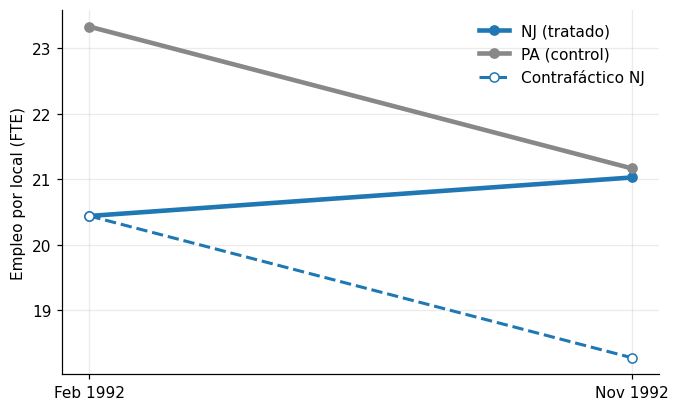

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot([0, 1], tabla.loc['NJ', ['Feb 92', 'Nov 92']], 'o-', color=BLUE, lw=3, label='NJ (tratado)')
ax.plot([0, 1], tabla.loc['PA', ['Feb 92', 'Nov 92']], 'o-', color=GREY, lw=3, label='PA (control)')
cf = tabla.loc['NJ', 'Feb 92'] + tabla.loc['PA', 'Cambio']
ax.plot([0, 1], [tabla.loc['NJ', 'Feb 92'], cf], 'o--', color=BLUE, mfc='white', lw=2, label='Contrafáctico NJ')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Feb 1992', 'Nov 1992']); ax.set_ylabel('Empleo por local (FTE)'); ax.legend(frameon=False); plt.show()

**Lectura.** El empleo **cayó en PA** (control) y **no cayó en NJ**. El DD es **positivo** (≈ +2,75) y estable ante las variantes: no hay evidencia de pérdida de empleo. Pero el error estándar (≈ 1,3) es grande: el intervalo no descarta efectos moderados en ninguna dirección.

## 3. Tendencias paralelas

El supuesto clave: sin tratamiento, **tratadas y control habrían evolucionado igual**. No se puede testear directamente (es sobre contrafácticos), pero con **varios períodos previos** podemos mirar si venían separándose. Simulamos un panel de 8 períodos; el tratamiento ocurre en $t=5$.

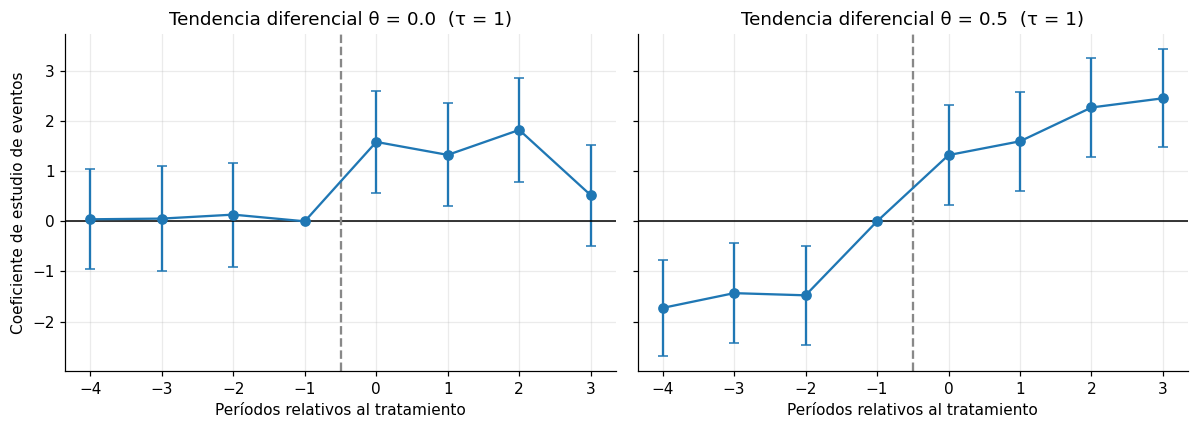

In [11]:
def panel_eventos(theta=0.0, tau=1.0, n=150, T=8, t0=5, sd=3.0, rng=rng):
    # tratadas y control; las tratadas tienen una tendencia diferencial lineal theta por período
    filas = []
    for G in (0, 1):
        for t in range(1, T + 1):
            y = 10 + 0.3 * t + 2 * G + theta * G * t + tau * G * (t >= t0) + rng.normal(0, sd, n)
            filas.append(pd.DataFrame({'y': y, 'G': G, 't': t}))
    return pd.concat(filas, ignore_index=True)

def estudio_eventos(d, t0=5, base=4):
    # coeficientes de interacción G x 1{t = s}, omitiendo la base (t0-1)
    X = pd.get_dummies(d.t, prefix='t', drop_first=True).astype(float)
    cols = []
    for s in sorted(d.t.unique()):
        if s == base: continue
        X[f'G_t{s}'] = (d.G * (d.t == s)).astype(float); cols.append((s, f'G_t{s}'))
    X['G'] = d.G; X = sm.add_constant(X)
    m = sm.OLS(d.y, X).fit(cov_type='HC1')
    out = pd.DataFrame({'t': [s for s, _ in cols], 'coef': [m.params[c] for _, c in cols], 'se': [m.bse[c] for _, c in cols]})
    out.loc[len(out)] = [base, 0.0, 0.0]
    return out.sort_values('t')

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, th in zip(axs, [0.0, 0.5]):
    es = estudio_eventos(panel_eventos(theta=th))
    ax.errorbar(es.t - 5, es.coef, yerr=1.96 * es.se, fmt='o-', color=BLUE, capsize=3)
    ax.axhline(0, color='k', lw=1); ax.axvline(-.5, color=GREY, ls='--'); ax.set_title(f'Tendencia diferencial θ = {th}  (τ = 1)')
    ax.set_xlabel('Períodos relativos al tratamiento')
axs[0].set_ylabel('Coeficiente de estudio de eventos'); plt.tight_layout(); plt.show()

Con $\theta=0$, las pre-tendencias son planas y los coeficientes post estiman $\tau=1$. Con $\theta=0{,}5$ las **pre-tendencias suben** y los coeficientes post están **sesgados hacia arriba**.

### Pre-tendencias: necesarias, no suficientes (poca potencia)

Roth (2022): un test de pre-tendencias que **no rechaza** puede convivir con sesgos materiales. Simulamos la potencia del test conjunto de pre-tendencias, con una tendencia diferencial $\theta$ por período (y el sesgo que genera en el DD).

In [12]:
from scipy import stats
def potencia_pretrend(theta, R=400, n=100, T0=4, sd=3.0, tau=1.0):
    rech = 0; sesgo = []
    for _ in range(R):
        times = np.arange(-T0, 1)
        yt = theta * times[None, :] + rng.normal(0, sd, (n, len(times))); yc = rng.normal(0, sd, (n, len(times)))
        yt[:, -1] += tau
        d = yt.mean(0) - yc.mean(0); se = np.sqrt(2 * sd**2 / n)
        pre = d[:-2] - d[-2]                                 # coeficientes pre respecto de t = -1
        V = se**2 * (np.eye(len(pre)) + 1)
        chi = pre @ np.linalg.solve(V, pre)
        rech += chi > stats.chi2.ppf(.95, len(pre)); sesgo.append(d[-1] - d[-2] - tau)
    return rech / R, np.mean(sesgo)

res = pd.DataFrame([(th, *potencia_pretrend(th)) for th in [0, .1, .2, .3, .5, .75, 1.0]], columns=['theta', 'rechazo_pretest', 'sesgo_DD'])
res['sesgo_relativo_a_tau'] = res.sesgo_DD / 1.0
res.round(2)

,theta,rechazo_pretest,sesgo_DD,sesgo_relativo_a_tau
0,0.00,0.06,-0.01,-0.01
1,0.10,0.07,0.07,0.07
2,0.20,0.10,0.17,0.17
3,0.30,0.24,0.32,0.32
4,0.50,0.60,0.53,0.53
5,0.75,0.92,0.78,0.78
6,1.00,1.00,1.06,1.06


Con $\theta=0{,}2$ el DD está sesgado en un 20% del efecto verdadero y el test rechaza apenas ~10% de las veces: **pre-tendencias planas no prueban nada**. La pregunta útil es *cuán grande tendría que ser una violación para revertir mi conclusión* (Rambachan y Roth, *HonestDiD*).

### La forma funcional importa: niveles vs. logs

Dos grupos **sin ningún efecto** que crecen 10% en el tiempo: en niveles, los dos no son paralelos.

In [13]:
A0, B0, g = 100, 200, np.exp(0.10)
A1, B1 = A0 * g, B0 * g
print('DD en niveles :', round((B1 - B0) - (A1 - A0), 2), '  (el efecto verdadero es 0)')
print('DD en logs    :', round((np.log(B1) - np.log(B0)) - (np.log(A1) - np.log(A0)), 2))

DD en niveles : 10.52   (el efecto verdadero es 0)
DD en logs    : 0.0


### Errores estándar: la trampa de la correlación serial (Bertrand, Duflo y Mullainathan, 2004)

Datos de 50 unidades y 10 períodos **sin efecto**; el error tiene correlación serial $\rho=0{,}8$. Medimos con qué frecuencia el test rechaza $H_0$ (la verdadera) al 5%.

In [14]:
def rechazo_se(S=300, G=50, T=10, rho=.8):
    rej = dict(usual=0, cluster=0, colapsado=0)
    for _ in range(S):
        a = rng.normal(0, 1, (G, 1)); e = np.zeros((G, T)); e[:, 0] = rng.normal(0, 1, G)
        for t in range(1, T): e[:, t] = rho * e[:, t - 1] + rng.normal(0, np.sqrt(1 - rho**2), G)
        y = a + e; treat = np.r_[np.ones(G // 2), np.zeros(G - G // 2)]; post = (np.arange(T) >= T // 2).astype(float)
        df = pd.DataFrame({'y': y.ravel(), 'g': np.repeat(np.arange(G), T), 't': np.tile(np.arange(T), G),
                           'D': np.outer(treat, post).ravel()})
        X = pd.get_dummies(df[['g', 't']].astype(str), drop_first=True).astype(float); X['D'] = df.D; X = sm.add_constant(X)
        m1 = sm.OLS(df.y, X).fit(); m2 = sm.OLS(df.y, X).fit(cov_type='cluster', cov_kwds={'groups': df.g})
        rej['usual'] += abs(m1.tvalues['D']) > 1.96; rej['cluster'] += abs(m2.tvalues['D']) > 2.01
        dd = pd.DataFrame({'d': y[:, T // 2:].mean(1) - y[:, :T // 2].mean(1), 'tr': treat}); m3 = smf.ols('d ~ tr', dd).fit()
        rej['colapsado'] += abs(m3.tvalues['tr']) > 2.01
    return {k: v / S for k, v in rej.items()}
print({k: f'{100*v:.0f}%' for k, v in rechazo_se().items()})

{'usual': '32%', 'cluster': '6%', 'colapsado': '6%'}


## 4. MLDA: edad mínima legal para beber

En los años 70 varios estados de EE.UU. **bajaron** la edad mínima para tomar alcohol de 21 a 18, en **fechas distintas**. Con datos de panel de 51 estados (1970--1983), estimamos el efecto sobre las **muertes cada 100.000** de jóvenes de 18--20 años. La variable `legal` es la proporción de 18--20 años autorizados a beber en el estado y año.

$$Y_{st}=\gamma_s+\lambda_t+\delta\,\text{LEGAL}_{st}+\varepsilon_{st}$$
(Los datos son los de *Mastering 'Metrics*; replicamos la Tabla 5.2 de Angrist y Pischke.)

In [15]:
ml = leer('mlda_mortalidad.csv')
print(ml.state.nunique(), 'estados;', ml.year.min(), '-', ml.year.max())
ml[ml.dtype == 'MVA'].head(3)

51 estados; 1970 - 1983


,year,state,dtype,count,pop,legal,mrate
1,1970,1,MVA,118,189770,0.0,62.181
7,1971,1,MVA,122,195623,0.0,62.365
13,1972,1,MVA,148,200988,0.0,73.636


In [16]:
espec = [('Base', 'mrate ~ legal + C(state) + C(year)', False),
         ('+ tendencias estatales', 'mrate ~ legal + C(state) + C(year) + C(state):year', False),
         ('+ pesos (población)', 'mrate ~ legal + C(state) + C(year)', True),
         ('+ ambos', 'mrate ~ legal + C(state) + C(year) + C(state):year', True)]
res = {}
for causa, nombre in [('all', 'Todas las muertes'), ('MVA', 'Accidentes de tránsito'), ('suicide', 'Suicidios'), ('internal', 'Causas internas (placebo)')]:
    s = ml[ml.dtype == causa]
    fila = {}
    for nm, f, pesos in espec:
        m = (smf.wls(f, s, weights=s['pop']) if pesos else smf.ols(f, s)).fit(cov_type='cluster', cov_kwds={'groups': s.state})
        fila[nm] = f"{m.params['legal']:.2f} ({m.bse['legal']:.2f})"
    res[nombre] = fila
pd.DataFrame(res).T

,Base,+ tendencias estatales,+ pesos (población),+ ambos
Todas las muertes,10.80 (4.59),8.47 (5.10),12.41 (4.60),9.65 (4.65)
Accidentes de tránsito,7.59 (2.50),6.64 (2.66),7.50 (2.27),6.46 (2.24)
Suicidios,0.59 (0.59),0.47 (0.80),1.49 (0.88),1.26 (0.89)
Causas internas (placebo),1.33 (1.59),0.08 (1.93),1.89 (1.78),1.28 (1.45)


Los números coinciden con la Tabla 5.2 publicada. Observaciones:

- El efecto sobre **accidentes de tránsito** (6--8 muertes por 100.000) **sobrevive** a las tendencias estatales y a los pesos: esa robustez es lo que da credibilidad a un DD.
- **Causas internas** (que no deberían depender de la MLDA) dan efectos chicos y no significativos: un **placebo** razonable.
- Con tendencias estatales aumentan los errores estándar: se exige más a los datos.

### Gráfico: ¿cómo se ven los datos?

Estados que ya permitían beber a los 18 en 1970, los que pasan a permitirlo entre 1970 y 1975 y los que nunca lo permiten:

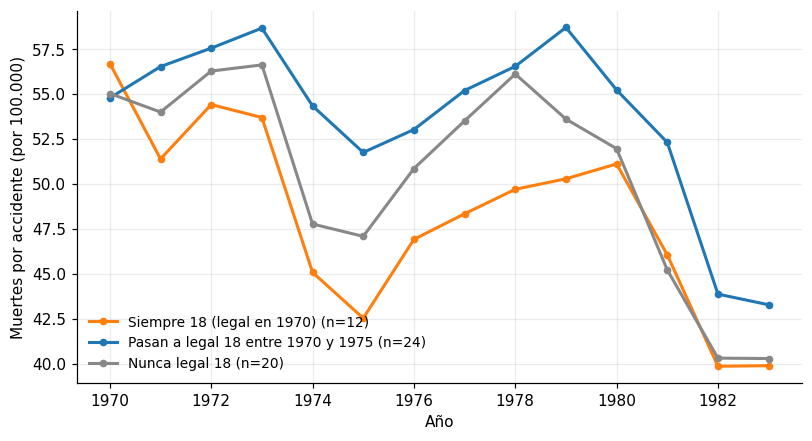

In [17]:
leg = ml[ml.dtype == 'MVA'].pivot(index='state', columns='year', values='legal')
grupos = {'Siempre 18 (legal en 1970)': leg.index[leg[1970] > .5],
          'Pasan a legal 18 entre 1970 y 1975': leg.index[(leg[1970] < .5) & (leg[1975] > .5)],
          'Nunca legal 18': leg.index[(leg[1970] < .5) & (leg[1983] < .5)]}
mva = ml[ml.dtype == 'MVA']
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for (nom, idx), c in zip(grupos.items(), [ORANGE, BLUE, GREY]):
    s = mva[mva.state.isin(idx)].groupby('year').apply(lambda z: np.average(z.mrate, weights=z['pop']))
    ax.plot(s.index, s.values, 'o-', color=c, label=f'{nom} (n={len(idx)})', lw=2, ms=4)
ax.set_ylabel('Muertes por accidente (por 100.000)'); ax.set_xlabel('Año'); ax.legend(frameon=False, fontsize=9); plt.show()

## 5. Diseños escalonados: TWFE, Goodman-Bacon y Callaway--Sant'Anna

El asistente de IA llega a las regiones **en distintas fechas**: cohorte **temprana** (trimestre 4), **tardía** (trimestre 7) y **nunca tratados**. Replicamos el DGP del dashboard del libro: 10 trimestres, 100 regiones por cohorte.

Tres escenarios para el efecto del tratamiento:

- **Homogéneo**: $\tau=20$ para todas las cohortes.
- **Heterogéneo**: $\tau=30$ la cohorte temprana, $\tau=15$ la tardía.
- **Dinámico**: crece con el tiempo desde la adopción, $\tau(e)=\min\{5(e+1),20\}$.

In [18]:
T, COHORTES, N = 10, (4, 7), 100

def generar_panel(efecto, seed=1):
    r = np.random.default_rng(seed); filas = []; uid = 0
    for g in (0,) + COHORTES:
        for _ in range(N):
            mu = r.normal(0, 5)
            for t in range(1, T + 1):
                eff = 0.0
                if g and t >= g:
                    if efecto == 'homogeneo': eff = 20
                    elif efecto == 'heterogeneo': eff = {4: 30, 7: 15}[g]
                    else: eff = min((t - g + 1) * 5, 20)
                filas.append((uid, t, g, 50 + mu + 0.5 * t + eff + r.normal(0, 3), eff))
            uid += 1
    return pd.DataFrame(filas, columns=['id', 't', 'g', 'y', 'efecto'])

def twfe(d):
    d = d.assign(D=((d.g > 0) & (d.t >= d.g)).astype(float))
    # within estimator: restamos medias por unidad y por tiempo
    y = d.y - d.groupby('id').y.transform('mean') - d.groupby('t').y.transform('mean') + d.y.mean()
    D = d.D - d.groupby('id').D.transform('mean') - d.groupby('t').D.transform('mean') + d.D.mean()
    return float((D * y).sum() / (D * D).sum())

def att_verdadero(d):
    return d.loc[(d.g > 0) & (d.t >= d.g), 'efecto'].mean()

### Callaway--Sant'Anna a mano

El bloque básico es el efecto sobre la cohorte $g$ en el período $t$,
$$ATT(g,t)=\big[\bar Y_{g,t}-\bar Y_{g,g-1}\big]-\big[\bar Y_{C,t}-\bar Y_{C,g-1}\big],$$
un DD $2\times2$ contra un grupo **limpio** $C$ (nunca tratados o aún no tratados). Después se **agrega** con pesos que uno controla.

In [19]:
def cs_cells(W, G, control='never'):
    # W: unidades x períodos (columnas = períodos); G: cohorte de cada unidad (0 = nunca tratada)
    out = {}
    for g in sorted(set(G[G > 0])):
        base = g - 1
        for t in W.columns:
            if t == base: continue
            ctrl = (G == 0) if control == 'never' else ((G == 0) | ((G > t) & (G != g)))
            dY = W[t] - W[base]
            out[(g, t)] = dY[G == g].mean() - dY[ctrl].mean()
    return out

def cs_agregar(cells, tam):
    post = {k: v for k, v in cells.items() if k[1] >= k[0]}
    simple = sum(v * tam[k[0]] for k, v in post.items()) / sum(tam[k[0]] for k in post)
    por_cohorte = {g: np.mean([v for k, v in post.items() if k[0] == g]) for g in tam}
    dinamico = {}
    for e in sorted({k[1] - k[0] for k in cells}):
        ks = [k for k in cells if k[1] - k[0] == e]
        dinamico[e] = sum(cells[k] * tam[k[0]] for k in ks) / sum(tam[k[0]] for k in ks)
    return dict(simple=simple, por_cohorte=por_cohorte, dinamico=dinamico)

def cs(d, control='never', y='y', idc='id', tc='t', gc='g', B=0, seed=0):
    W = d.pivot(index=idc, columns=tc, values=y); G = d.groupby(idc)[gc].first().loc[W.index]
    tam = G[G > 0].value_counts().to_dict()
    cells = cs_cells(W, G, control); agg = cs_agregar(cells, tam)
    if B:  # bootstrap por unidad para errores estándar
        r = np.random.default_rng(seed); bs = []
        for _ in range(B):
            ix = r.integers(0, len(W), len(W)); Wb = W.iloc[ix].reset_index(drop=True); Gb = G.iloc[ix].reset_index(drop=True)
            tb = Gb[Gb > 0].value_counts().to_dict(); cb = cs_cells(Wb, Gb, control); bs.append(cs_agregar(cb, tb))
        agg['se_simple'] = np.std([b['simple'] for b in bs], ddof=1)
        agg['se_dinamico'] = {e: np.std([b['dinamico'][e] for b in bs if e in b['dinamico']], ddof=1) for e in agg['dinamico']}
        agg['se_cohorte'] = {g: np.std([b['por_cohorte'][g] for b in bs], ddof=1) for g in tam}
    return cells, agg

filas = []
paneles = {}
for ef in ['homogeneo', 'heterogeneo', 'dinamico']:
    d = generar_panel(ef); paneles[ef] = d
    cells, agg = cs(d)
    filas.append({'efectos': ef, 'ATT verdadero': att_verdadero(d), 'TWFE': twfe(d), 'C&S (nunca tr.)': agg['simple'], 'C&S (aún no tr.)': cs(d, 'notyet')[1]['simple']})
pd.DataFrame(filas).set_index('efectos').round(2)

,ATT verdadero,TWFE,C&S (nunca tr.),C&S (aún no tr.)
efectos,,,,
homogeneo,20.00,19.73,19.74,19.70
heterogeneo,24.55,21.55,24.29,24.25
dinamico,14.55,11.10,14.29,14.25


- Con efectos **homogéneos**, TWFE y C&S coinciden con el ATT verdadero.
- Con efectos **heterogéneos o dinámicos**, TWFE se aleja; C&S se mantiene cerca del ATT.

### ¿Por qué? La descomposición de Goodman-Bacon

$\hat\tau_{TWFE}$ es un **promedio ponderado de todos los DD $2\times2$** posibles. Con dos cohortes y un grupo nunca tratado hay **cuatro** comparaciones; la última es la problemática: la cohorte tardía usa como **control** a la temprana, que **ya está tratada**.

In [20]:
def goodman_bacon(d):
    # descomposición exacta (panel balanceado, timing groups): devuelve cada DD 2x2, su peso y el tipo de comparación
    T = d.t.max(); ids = d.groupby('g').id.nunique(); Ntot = ids.sum(); gs = [g for g in sorted(ids.index) if g > 0]
    Dbar = {g: (T - g + 1) / T for g in gs}
    m = lambda g, a, b: d[(d.g == g) & (d.t >= a) & (d.t <= b)].y.mean()
    out = []
    for k in gs:      # k contra nunca tratados
        nk, nU = ids[k] / Ntot, ids[0] / Ntot; nkU = nk / (nk + nU)
        w = (nk + nU)**2 * nkU * (1 - nkU) * Dbar[k] * (1 - Dbar[k])
        est = (m(k, k, T) - m(k, 1, k - 1)) - (m(0, k, T) - m(0, 1, k - 1))
        out.append(dict(tipo='Tratada vs. nunca tratados', k=k, l=0, peso=w, DD=est))
    for i, k in enumerate(gs):
        for l in gs[i + 1:]:
            nk, nl = ids[k] / Ntot, ids[l] / Ntot; nkl = nk / (nk + nl)
            w1 = ((nk + nl) * (1 - Dbar[l]))**2 * nkl * (1 - nkl) * ((Dbar[k] - Dbar[l]) / (1 - Dbar[l])) * ((1 - Dbar[k]) / (1 - Dbar[l]))
            e1 = (m(k, k, l - 1) - m(k, 1, k - 1)) - (m(l, k, l - 1) - m(l, 1, k - 1))
            w2 = ((nk + nl) * Dbar[k])**2 * nkl * (1 - nkl) * (Dbar[l] / Dbar[k]) * ((Dbar[k] - Dbar[l]) / Dbar[k])
            e2 = (m(l, l, T) - m(l, k, l - 1)) - (m(k, l, T) - m(k, k, l - 1))
            out.append(dict(tipo='Temprana vs. tardía (limpia)', k=k, l=l, peso=w1, DD=e1))
            out.append(dict(tipo='Tardía vs. temprana (PROHIBIDA)', k=k, l=l, peso=w2, DD=e2))
    r = pd.DataFrame(out); r['peso'] = r.peso / r.peso.sum()
    return r

for ef in ['homogeneo', 'heterogeneo', 'dinamico']:
    gb = goodman_bacon(paneles[ef])
    print(f'--- {ef}: Σ peso × DD = {(gb.peso * gb.DD).sum():.2f}   |   TWFE = {twfe(paneles[ef]):.2f}')
    print(gb[['tipo', 'peso', 'DD']].round(3).to_string(index=False))

--- homogeneo: Σ peso × DD = 19.73   |   TWFE = 19.73
                           tipo  peso     DD
     Tratada vs. nunca tratados 0.318 20.109
     Tratada vs. nunca tratados 0.364 19.712
   Temprana vs. tardía (limpia) 0.136 19.523
Tardía vs. temprana (PROHIBIDA) 0.182 19.283
--- heterogeneo: Σ peso × DD = 21.55   |   TWFE = 21.55
                           tipo  peso     DD
     Tratada vs. nunca tratados 0.318 30.109
     Tratada vs. nunca tratados 0.364 14.712
   Temprana vs. tardía (limpia) 0.136 29.523
Tardía vs. temprana (PROHIBIDA) 0.182 14.283
--- dinamico: Σ peso × DD = 11.10   |   TWFE = 11.10
                           tipo  peso     DD
     Tratada vs. nunca tratados 0.318 15.823
     Tratada vs. nunca tratados 0.364 12.212
   Temprana vs. tardía (limpia) 0.136  9.523
Tardía vs. temprana (PROHIBIDA) 0.182  1.783


La suma ponderada reproduce **exactamente** el coeficiente TWFE (¡es una identidad!). En el escenario dinámico, la comparación prohibida tiene un DD **mucho más bajo** que las otras: el control (cohorte temprana) ya viene acumulando efecto, y restarlo achica la estimación.

### Estudio de eventos: TWFE vs. Callaway--Sant'Anna

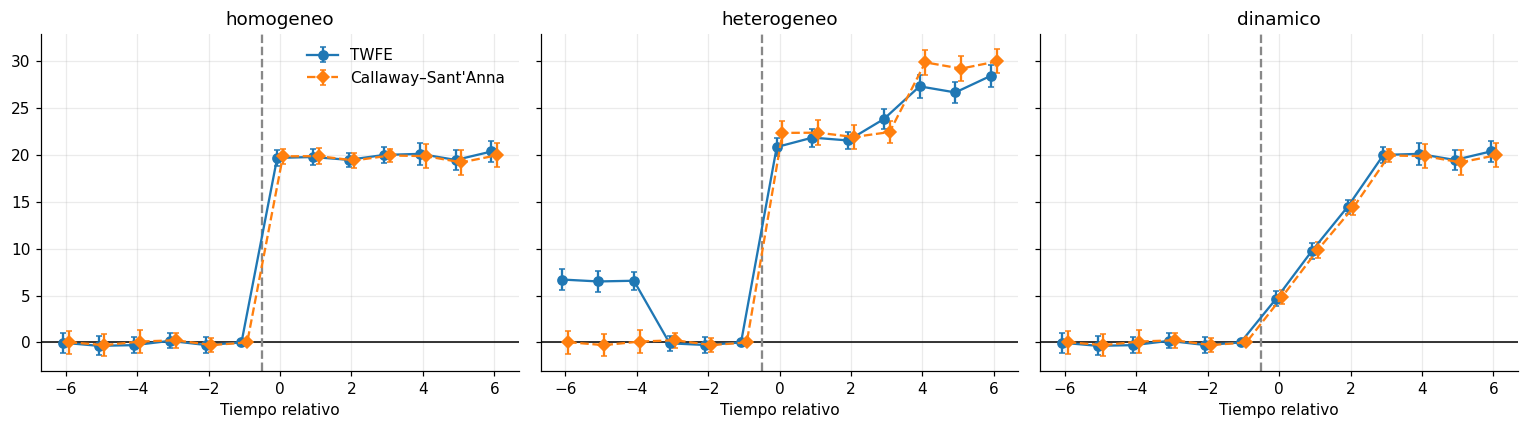

In [21]:
def evento_twfe(d):
    d = d.assign(rel=np.where(d.g > 0, d.t - d.g, -999))
    rels = sorted(r for r in d.rel.unique() if r not in (-1, -999))
    X = pd.get_dummies(d[['id', 't']].astype(str), drop_first=True).astype(float)
    for r in rels: X[f'r{r}'] = (d.rel == r).astype(float)
    m = sm.OLS(d.y, sm.add_constant(X)).fit(cov_type='cluster', cov_kwds={'groups': d.id})
    out = pd.DataFrame({'e': rels, 'coef': [m.params[f'r{r}'] for r in rels], 'se': [m.bse[f'r{r}'] for r in rels]})
    out.loc[len(out)] = [-1, 0.0, 0.0]; return out.sort_values('e')

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, ef in zip(axs, ['homogeneo', 'heterogeneo', 'dinamico']):
    d = paneles[ef]; et = evento_twfe(d); _, agg = cs(d, B=100)
    ec = pd.DataFrame({'e': list(agg['dinamico']), 'coef': list(agg['dinamico'].values()), 'se': [agg['se_dinamico'][e] for e in agg['dinamico']]})
    ec.loc[len(ec)] = [-1, 0.0, 0.0]; ec = ec.sort_values('e')
    ax.errorbar(et.e - .08, et.coef, yerr=1.96 * et.se, fmt='o-', color=BLUE, capsize=2, label='TWFE')
    ax.errorbar(ec.e + .08, ec.coef, yerr=1.96 * ec.se, fmt='D--', color=ORANGE, capsize=2, label="Callaway–Sant'Anna")
    ax.axhline(0, color='k', lw=1); ax.axvline(-.5, color=GREY, ls='--'); ax.set_title(ef); ax.set_xlabel('Tiempo relativo')
axs[0].legend(frameon=False); plt.tight_layout(); plt.show()

### Un ejemplo donde TWFE se equivoca feo

Tres cohortes y efectos que **crecen mucho** en la temprana (4 por período) y poco en la tardía (1 por período): la comparación prohibida resta una cantidad enorme.

In [22]:
def panel_dyn(N=100, T=12, cohortes=(3, 6), pend=(4, 1), seed=1):
    r = np.random.default_rng(seed); filas = []; uid = 0
    for g in (0,) + cohortes:
        for _ in range(N):
            mu = r.normal(0, 3)
            for t in range(1, T + 1):
                eff = pend[cohortes.index(g)] * (t - g + 1) if g and t >= g else 0.0
                filas.append((uid, t, g, 50 + mu + 0.3 * t + eff + r.normal(0, 2), eff))
            uid += 1
    return pd.DataFrame(filas, columns=['id', 't', 'g', 'y', 'efecto'])
pd_ = panel_dyn()
print('ATT verdadero:', round(att_verdadero(pd_), 1), '| TWFE:', round(twfe(pd_), 1), '| C&S:', round(cs(pd_)[1]['simple'], 1))

ATT verdadero: 14.6 | TWFE: 3.6 | C&S: 14.4


## 6. Salario mínimo y empleo en condados (`mpdta`)

Datos de Callaway y Sant'Anna (2021): panel de **500 condados** de EE.UU. entre 2003 y 2007 (resultado: log del empleo adolescente). Distintos estados suben el salario mínimo en **distintos años** (2004, 2006, 2007), y hay condados **nunca tratados**.

                condados
g                       
nunca tratados       309
2004                  20
2006                  40
2007                 131


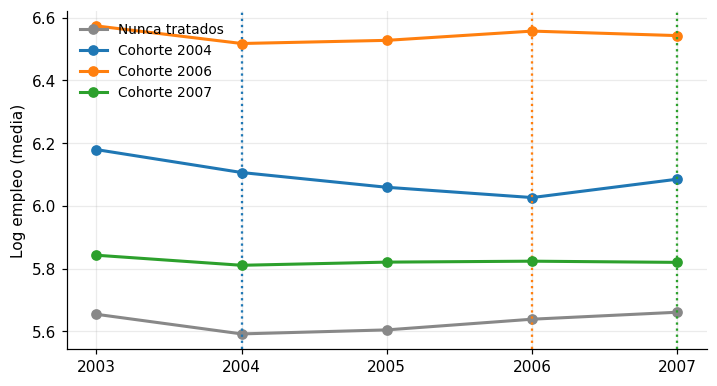

In [23]:
mp = leer('mpdta_salario_minimo.csv').rename(columns={'countyreal': 'id', 'year': 't', 'first_treat': 'g', 'lemp': 'y'})
mp['D'] = ((mp.g > 0) & (mp.t >= mp.g)).astype(int)
print(mp.groupby('g').id.nunique().rename({0: 'nunca tratados'}).to_frame('condados'))
fig, ax = plt.subplots(figsize=(7.5, 4))
for g, c, nm in [(0, GREY, 'Nunca tratados'), (2004, BLUE, 'Cohorte 2004'), (2006, ORANGE, 'Cohorte 2006'), (2007, GREEN, 'Cohorte 2007')]:
    s = mp[mp.g == g].groupby('t').y.mean(); ax.plot(s.index, s.values, 'o-', color=c, label=nm, lw=2)
    if g: ax.axvline(g, color=c, ls=':')
ax.set_xticks(range(2003, 2008)); ax.set_ylabel('Log empleo (media)'); ax.legend(frameon=False, fontsize=9); plt.show()

In [24]:
tw = smf.ols('y ~ D + C(id) + C(t)', mp).fit(cov_type='cluster', cov_kwds={'groups': mp.id})
cells, agg = cs(mp, B=200)
print('TWFE                    : %.3f (EE %.3f)' % (tw.params['D'], tw.bse['D']))
print('C&S, agregación simple  : %.3f (EE %.3f)   [R/did: -0.040]' % (agg['simple'], agg['se_simple']))
print('C&S, aún no tratados    : %.3f' % cs(mp, 'notyet')[1]['simple'])
print('\nPor cohorte:'); print(pd.DataFrame({'ATT': agg['por_cohorte'], 'EE': agg['se_cohorte']}).round(3))

TWFE                    : -0.037 (EE 0.015)
C&S, agregación simple  : -0.040 (EE 0.012)   [R/did: -0.040]
C&S, aún no tratados    : -0.040

Por cohorte:
        ATT     EE
2007 -0.026  0.017
2006 -0.023  0.018
2004 -0.080  0.027


In [25]:
att_gt = pd.DataFrame([{'g': k[0], 't': k[1], 'att': v} for k, v in cells.items()]).pivot(index='g', columns='t', values='att')
print('ATT(g,t): cada celda es un DD 2x2 contra los nunca tratados, con base g-1'); att_gt.round(3)

ATT(g,t): cada celda es un DD 2x2 contra los nunca tratados, con base g-1


t,2003,2004,2005,2006,2007
g,,,,,
2004,NaN,-0.011,-0.070,-0.137,-0.101
2006,-0.004,0.003,NaN,-0.005,-0.041
2007,0.003,0.034,0.031,NaN,-0.026


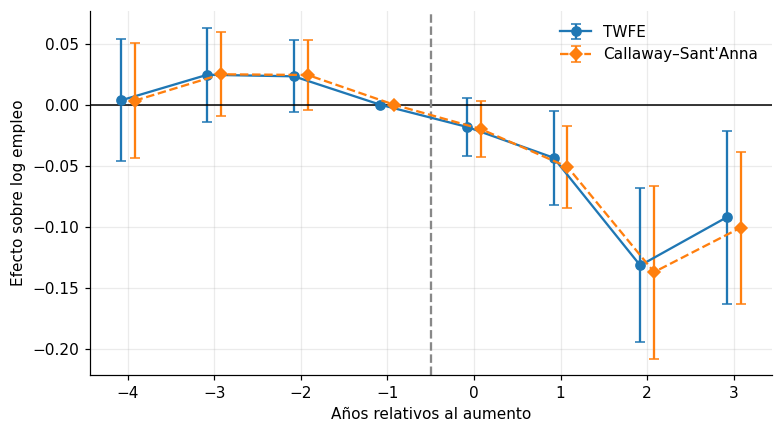

In [26]:
et = evento_twfe(mp.assign(g=mp.g))
ec = pd.DataFrame({'e': list(agg['dinamico']), 'coef': list(agg['dinamico'].values()), 'se': [agg['se_dinamico'][e] for e in agg['dinamico']]})
ec.loc[len(ec)] = [-1, 0.0, 0.0]; ec = ec.sort_values('e')
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.errorbar(et.e - .08, et.coef, yerr=1.96 * et.se, fmt='o-', color=BLUE, capsize=3, label='TWFE')
ax.errorbar(ec.e + .08, ec.coef, yerr=1.96 * ec.se, fmt='D--', color=ORANGE, capsize=3, label="Callaway–Sant'Anna")
ax.axhline(0, color='k', lw=1); ax.axvline(-.5, color=GREY, ls='--'); ax.set_xlabel('Años relativos al aumento'); ax.set_ylabel('Efecto sobre log empleo'); ax.legend(frameon=False); plt.show()

**Lectura.** El efecto es **negativo**, **pequeño al principio** y se **acumula** (≈ −0,13 a los dos años). Un único número (TWFE: −0,037; C&S simple: −0,040) **esconde esa dinámica**. En estos datos TWFE y C&S son parecidos; **eso no se sabe antes de mirar**, y por eso conviene siempre reportar un estimador robusto junto con la descomposición de Goodman-Bacon.

## 7. Alquileres en CABA y COVID

Caso de la edición anterior. Una hipótesis: tras el COVID (marzo 2020), los departamentos con **espacio al aire libre** (patio o terraza) se volvieron más valiosos. Con avisos de alquiler de CABA entre mayo de 2019 y mayo de 2020, comparamos la **variación de precios** de los departamentos con y sin espacio al aire libre, antes y después de la cuarentena (`postcovid`).

- Tratadas: `airelibre = 1`. Control: `airelibre = 0`.
- Los precios son **nominales en pesos** y hay inflación: la tendencia común $\lambda$ es grande, pero el DD la **cancela** si afecta igual a ambos grupos.

In [27]:
al = leer('alquileres_caba_covid.csv')
al['airelibre'] = np.where((al.patio.astype(str) == '1') | (al.terraza.astype(str) == '1'), 1, 0)
al['logprice'] = np.log(al.price)
al['l3'] = al.l3.astype('category')   # (patsy no lee bien el dtype string nuevo de pandas)
print(len(al), 'avisos;', al.airelibre.mean().round(2), 'con espacio al aire libre')
al.groupby(['airelibre', 'postcovid']).agg(precio_medio=('price', 'mean'), logprecio=('logprice', 'mean'), n=('price', 'size')).round(2)

15099 avisos; 0.22 con espacio al aire libre


precio_medio  logprecio      n
airelibre postcovid                                
0         0              23711.66       9.93  10951
          1              32283.41      10.22    880
1         0              27953.04      10.08   2980
          1              39623.20      10.38    288

In [28]:
m = al.groupby(['airelibre', 'postcovid']).logprice.mean().unstack()
print('DD en logs (a mano):', round((m.loc[1, 1] - m.loc[1, 0]) - (m.loc[0, 1] - m.loc[0, 0]), 4))
r = smf.ols('logprice ~ postcovid * airelibre', al).fit(cov_type='HC1')
print('Regresión: %.4f (EE %.4f)' % (r.params['postcovid:airelibre'], r.bse['postcovid:airelibre']))
r2 = smf.ols('logprice ~ postcovid * airelibre + np.log(surface_to) + rooms + C(l3)', al).fit(cov_type='HC1')
print('Con controles (superficie, ambientes, barrio): %.4f (EE %.4f)' % (r2.params['postcovid:airelibre'], r2.bse['postcovid:airelibre']))

DD en logs (a mano): 0.0172
Regresión: 0.0172 (EE 0.0406)
Con controles (superficie, ambientes, barrio): 0.0135 (EE 0.0227)


Inspección gráfica de las **tendencias** (promedios mensuales de log precio): ¿se movían juntos los dos grupos antes del COVID?

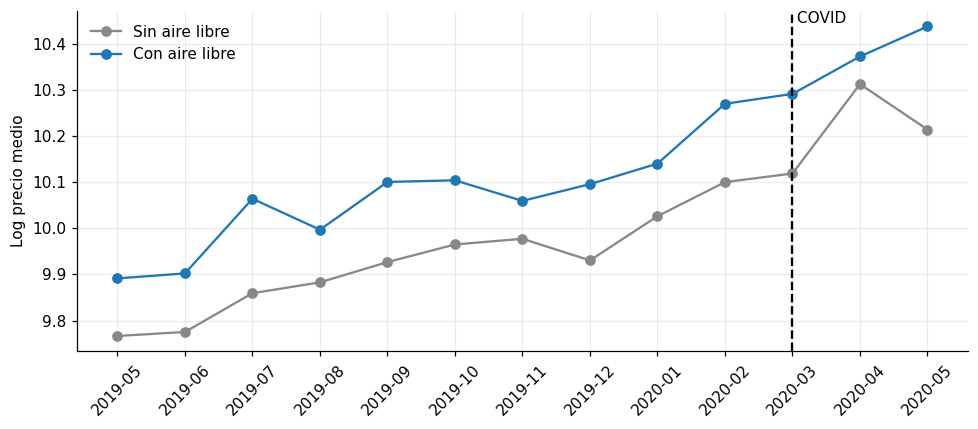

In [29]:
al['mes'] = pd.to_datetime(al.start_date).dt.to_period('M')
mm = al.groupby(['mes', 'airelibre']).logprice.mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mm.index.astype(str), mm[0], 'o-', color=GREY, label='Sin aire libre'); ax.plot(mm.index.astype(str), mm[1], 'o-', color=BLUE, label='Con aire libre')
ax.axvline('2020-03', color='k', ls='--'); ax.text('2020-03', ax.get_ylim()[1], ' COVID', va='top')
plt.xticks(rotation=45); ax.set_ylabel('Log precio medio'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Lectura.** El DD es chico (≈ +0,02) y **no es distinguible de cero** (EE ≈ 0,04). Pero hay muy pocas observaciones post-COVID (≈ 1.000 de 15.000), los precios mensuales son ruidosos y el grupo "con aire libre" cambió su composición. Es un buen ejemplo de **potencia limitada**: no rechazar no es lo mismo que encontrar que no hay efecto. Además, la serie mensual sirve de **inspección** de tendencias paralelas antes de marzo 2020.

## 8. Resumen

- **DD**: la variación del control es el contrafáctico de la variación del tratado. Cancela niveles y tendencia común.
- **Regresión**: el coeficiente de la interacción es idéntico a la doble diferencia; da errores estándar. **Agrupar** por la unidad de tratamiento.
- **Supuesto**: tendencias paralelas en $Y(0)$: es sobre contrafácticos, depende de la escala y las pre-tendencias **no lo prueban** (poca potencia).
- **Escalonado**: TWFE es un promedio de DD $2\times2$ con pesos que incluyen **comparaciones prohibidas**; con efectos heterogéneos o dinámicos puede fallar. Usar **Callaway--Sant'Anna** (u otros) y reportar el estudio de eventos.

## 9. Ejercicios

1. En el 2×2 simulado, fije $\delta=10$ y $\tau=0$. ¿Qué estima el DD? Con Monte Carlo, ¿qué proporción de veces rechaza $H_0:\tau=0$ al 5%?
2. Con los datos de Card y Krueger, estime el DD **solo con los locales del sur de NJ** (`southj`) contra PA. ¿Cambia el resultado?
3. En Card y Krueger, use como resultado el **precio de la comida** (`pentree`, `pentree2`): ¿hay evidencia de traslado a precios?
4. Con MLDA, repita la estimación para **homicidios** y comente: ¿es un buen placebo?
5. En el panel escalonado dinámico, calcule a mano el DD $2\times2$ "prohibido" (cohorte tardía vs. temprana en la ventana posterior) y compárelo con el ATT verdadero.
6. Cambie `COHORTES` a `(4, 5)` (muy cercanas): ¿cómo cambia el peso de la comparación prohibida?
7. Con `mpdta`, calcule el ATT por cohorte usando **aún no tratados** como control. ¿Qué cohorte es más sensible?
8. Con los alquileres, defina un **placebo temporal**: finja que el COVID empezó en noviembre de 2019 y repita el DD usando solo datos anteriores a marzo de 2020.
9. Reflexión: en un caso de su investigación, ¿por qué el grupo tratado fue tratado? ¿esa regla se relaciona con la tendencia del resultado?